In [1]:
import findspark, pyspark
from pyspark.sql import SparkSession

In [2]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = (SparkSession.builder
    .master("local[*]")
    .appName("IntroToSpark1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    # Optional: let Spark pick a free UI port instead of hardcoding 4040
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "0")
    .config("spark.driver.memory", "2g")
    .getOrCreate())

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/17 10:12:32 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
df = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')
df.show()

25/12/17 10:12:34 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

In [4]:
df.columns

['industry',
 'biweekly_period',
 'biweekly_index',
 'ticker',
 'longname',
 'benchmark',
 'period_start',
 'period_end',
 'period_open',
 'period_close',
 'period_high',
 'period_low',
 'avg_close',
 'period_return',
 'benchmark_period_return',
 'beta',
 'price_volatility',
 'return_volatility',
 'avg_intraday_range',
 'max_intraday_range',
 'total_volume',
 'avg_daily_volume',
 'max_daily_volume',
 'volume_volatility',
 'avg_volume_up_days',
 'avg_volume_down_days',
 'gap_count',
 'avg_gap_size',
 'max_gap',
 'up_days',
 'down_days',
 'financing_next_period',
 'has_property_acquisition',
 'has_exploration_results',
 'maturity',
 'avg_prChg',
 'price_deviation_from_year',
 'has_financing',
 'prev_period_return',
 'prev_price_volatility',
 'prev_avg_daily_volume',
 'prev_volume_volatility',
 'prev_gap_count',
 'prev_exploration_results',
 'prev_property_acquisition',
 'current_financing_announcement',
 'prev_financing_announcement',
 'second_prev_financing_announcement',
 'third_prev_f

In [5]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

stress_features = [
    "price_volatility",
    "return_volatility",
    "avg_intraday_range",
    "max_intraday_range",
    "gap_count",
    "avg_gap_size",
    "max_gap",
    "volatility_change",
    "return_change"
]

w_ticker = Window.partitionBy("ticker")

df_stress = df
for col in stress_features:
    df_stress = df_stress.withColumn(
        f"z_{col}",
        (F.col(col) - F.mean(col).over(w_ticker)) /
        F.stddev(col).over(w_ticker)
    )

In [6]:
z_cols = [F.col(f"z_{c}") for c in stress_features]

df_stress = df_stress.withColumn(
    "market_stress_index",
    sum(z_cols) / len(z_cols)
)

In [7]:
event_times = (
    df_stress
    .filter(F.col("financing_next_period") == 1)
    .select(F.col("biweekly_index").alias("anchor_index"))
    .distinct()
)
# A firm is "control at anchor_index" if it does NOT have financing_next_period==1 at that index
controls = (
    df_stress.alias("d")
    .join(event_times.alias("e"), F.col("d.biweekly_index") == F.col("e.anchor_index"))
    .filter(F.col("d.financing_next_period") == 0)   # ensure no event for that firm at that time
    .select(
        F.col("d.ticker"),
        F.col("e.anchor_index").alias("event_index")  # pseudo-event index
    )
)

# real events (one per firm event)
real_events = (
    df_stress
    .filter(F.col("financing_next_period") == 1)
    .select("ticker", (F.col("biweekly_index") + F.lit(1)).alias("event_index"))
)

anchors = (
    real_events.withColumn("is_financing_event", F.lit(1))
    .unionByName(controls.withColumn("is_financing_event", F.lit(0)))
)

df_event = (
    df_stress.join(anchors, on="ticker", how="inner")
    .withColumn("event_time", F.col("biweekly_index") - F.col("event_index"))
    .filter(F.col("event_time").between(-6, 3))
    .select("event_time", "is_financing_event", "market_stress_index")
)


In [8]:
df_event_pd = df_event.select(
    "event_time",
    "is_financing_event",
    "market_stress_index"
).toPandas()

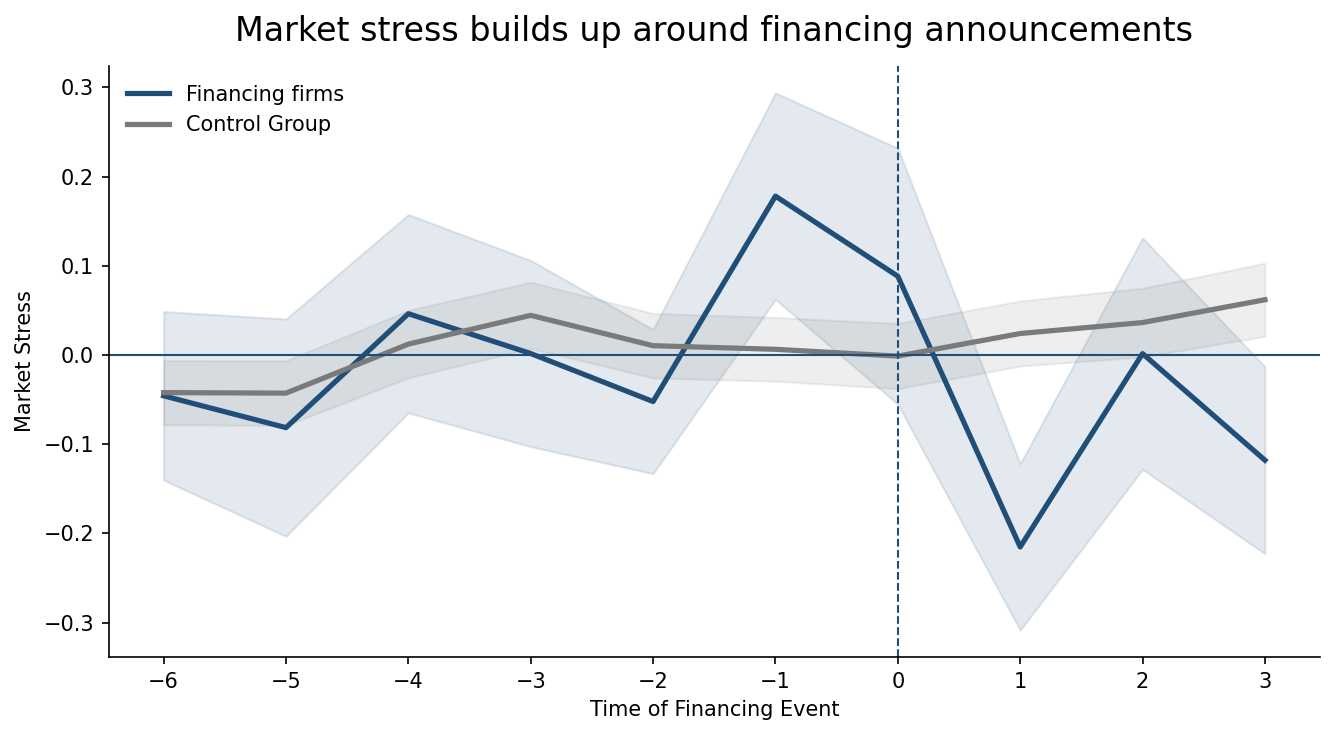

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# --- Aggregate (same as you did) ---
plot_df = (
    df_event_pd
    .groupby(["event_time", "is_financing_event"])
    .agg(
        mean_stress=("market_stress_index", "mean"),
        std_stress=("market_stress_index", "std"),
        n=("market_stress_index", "count")
    )
    .reset_index()
)

plot_df["se"] = plot_df["std_stress"] / np.sqrt(plot_df["n"])

# --- Ensure nice ordering on x-axis ---
plot_df = plot_df.sort_values(["is_financing_event", "event_time"])

fin = plot_df[plot_df["is_financing_event"] == 1].sort_values("event_time")
nonfin = plot_df[plot_df["is_financing_event"] == 0].sort_values("event_time")

# --- Professional figure layout ---
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

# Lines + uncertainty bands
ax.plot(fin["event_time"], fin["mean_stress"], linewidth=2.5, c="#1f4e79", label="Financing firms")
ax.fill_between(
    fin["event_time"],
    fin["mean_stress"] - fin["se"],
    fin["mean_stress"] + fin["se"],
    color="#1f4e79",
    alpha=0.12
)

ax.plot(nonfin["event_time"], nonfin["mean_stress"], linewidth=2.5, c="#7a7a7a", label="Control Group")
ax.fill_between(
    nonfin["event_time"],
    nonfin["mean_stress"] - nonfin["se"],
    nonfin["mean_stress"] + nonfin["se"],
    color="#7a7a7a", 
    alpha=0.12
)

# Reference lines
ax.axvline(0, linestyle="--", linewidth=1, c="#1f4e79")
ax.axhline(0, linestyle="-", linewidth=1, c="#1f4e79")

# Labels & title (slide-ready)
ax.set_title("Market stress builds up around financing announcements", pad=12, fontsize = 16)
ax.set_xlabel("Time of Financing Event")
ax.set_ylabel("Market Stress")

# Ticks: make sure every event_time is shown (clean for slides)
xticks = sorted(df_event_pd["event_time"].unique())
ax.set_xticks(xticks)

# Legend: clean placement, no box clutter
ax.legend(frameon=False, loc="upper left")

# Remove top/right spines for a modern look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

“This figure shows a market stress index built from volatility, gap risk, and intraperiod instability.
We align firms that announce financing to the period before the announcement, and compare them to a control group of firms that did not announce financing, anchored on the same calendar periods. 

We observe a clear and gradual buildup of stress in financing firms in the weeks leading up to the announcement, while control firms remain flat.
Importantly, stress peaks just before the announcement and drops afterwards, suggesting that financing announcements resolve uncertainty rather than create it.”

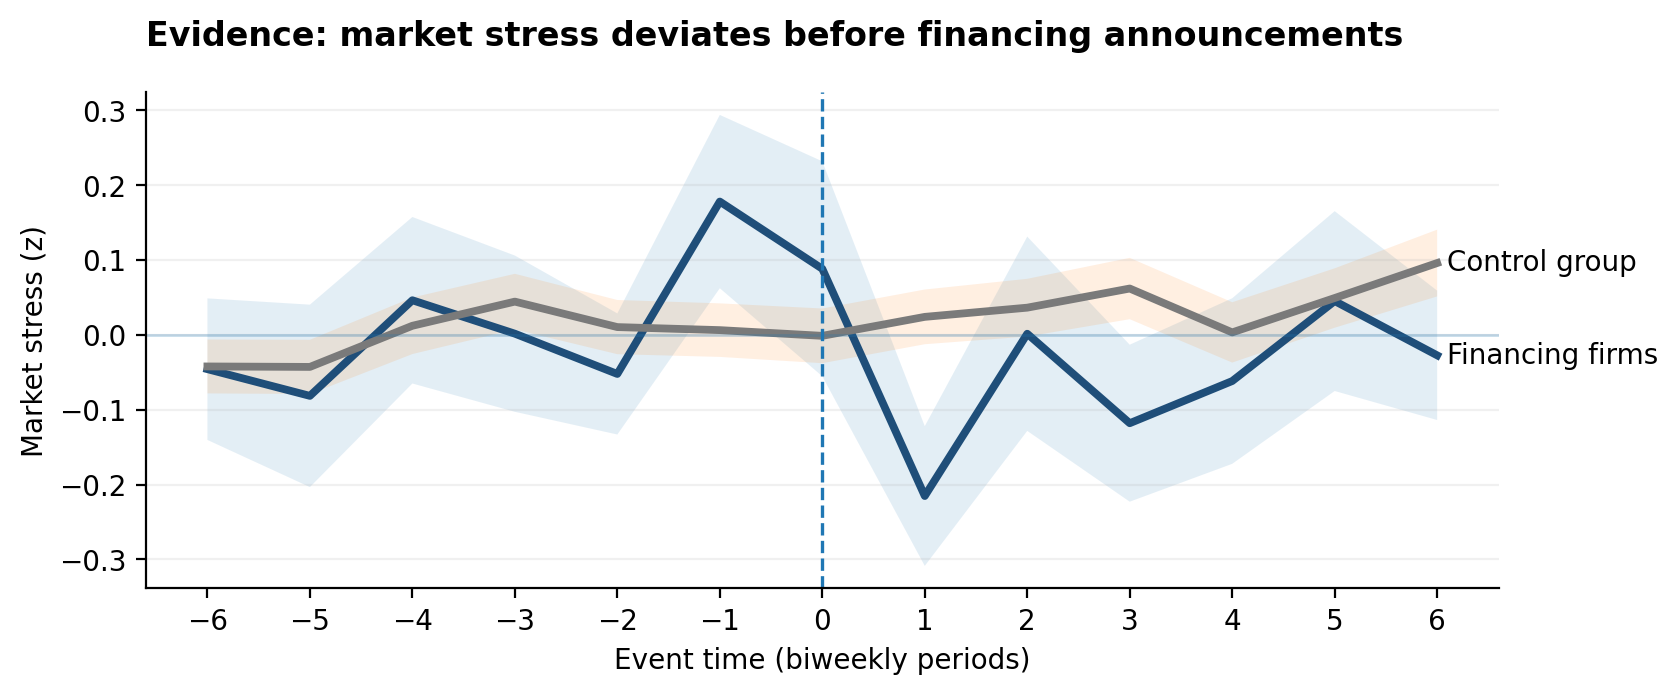

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Aggregate (same data & logic) ---
plot_df = (
    df_event_pd
    .groupby(["event_time", "is_financing_event"])
    .agg(
        mean_stress=("market_stress_index", "mean"),
        std_stress=("market_stress_index", "std"),
        n=("market_stress_index", "count")
    )
    .reset_index()
)

plot_df["se"] = plot_df["std_stress"] / np.sqrt(plot_df["n"])
plot_df = plot_df.sort_values(["is_financing_event", "event_time"])

fin = plot_df[plot_df["is_financing_event"] == 1].sort_values("event_time")
ctrl = plot_df[plot_df["is_financing_event"] == 0].sort_values("event_time")

# --- Figure: wider + shorter (fits right-column evidence panel) ---
fig, ax = plt.subplots(figsize=(8.5, 3.6), dpi=200)

# Uncertainty bands (lighter)
ax.fill_between(
    fin["event_time"],
    fin["mean_stress"] - fin["se"],
    fin["mean_stress"] + fin["se"],
    alpha=0.12,
    linewidth=0
)
ax.fill_between(
    ctrl["event_time"],
    ctrl["mean_stress"] - ctrl["se"],
    ctrl["mean_stress"] + ctrl["se"],
    alpha=0.12,
    linewidth=0
)

# Lines
ax.plot(fin["event_time"], fin["mean_stress"], c="#1f4e79", linewidth=2.8)
ax.plot(ctrl["event_time"], ctrl["mean_stress"], c="#7a7a7a", linewidth=2.8)

# Reference lines
ax.axvline(0, linestyle="--", linewidth=1.2)
ax.axhline(0, linestyle="-", linewidth=1, alpha=0.25)

# Axis labels (keep short; title handled as caption-like text)
ax.set_xlabel("Time of Financing Event")
ax.set_ylabel("Market stress")

# Ticks
xticks = sorted(df_event_pd["event_time"].unique())
ax.set_xticks(xticks)

# Grid: y only, subtle
ax.grid(True, axis="y", alpha=0.18)
ax.grid(False, axis="x")

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Caption-style heading (matches your slide style better than a plot title)
ax.text(
    0.0, 1.08,
    "Evidence: market stress deviates before financing announcements",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom"
)

# Inline labels instead of legend (cleaner for slides)
# Place labels near last points (robust to different ranges)
fin_last = fin.iloc[-1]
ctrl_last = ctrl.iloc[-1]
ax.text(fin_last["event_time"] + 0.1, fin_last["mean_stress"], "Financing firms", va="center")
ax.text(ctrl_last["event_time"] + 0.1, ctrl_last["mean_stress"], "Control group", va="center")

plt.tight_layout()
plt.show()

In [14]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# --- Aggregate (same data & logic) ---
plot_df = (
    df_event_pd
    .groupby(["event_time", "is_financing_event"])
    .agg(
        mean_stress=("market_stress_index", "mean"),
        std_stress=("market_stress_index", "std"),
        n=("market_stress_index", "count")
    )
    .reset_index()
)
plot_df["se"] = plot_df["std_stress"] / np.sqrt(plot_df["n"])
plot_df = plot_df.sort_values(["is_financing_event", "event_time"])

fin = plot_df[plot_df["is_financing_event"] == 1].sort_values("event_time")
ctrl = plot_df[plot_df["is_financing_event"] == 0].sort_values("event_time")

fig = go.Figure()

def add_line_with_band(df_line, name):
    x = df_line["event_time"]
    y = df_line["mean_stress"]
    se = df_line["se"]

    # band
    fig.add_trace(go.Scatter(
        x=pd.concat([x, x[::-1]]),
        y=pd.concat([y + se, (y - se)[::-1]]),
        fill="toself",
        mode="lines",
        line=dict(width=0),
        opacity=0.15,
        showlegend=False,
        name=f"{name} ± SE"
    ))
    # line
    fig.add_trace(go.Scatter(
        x=x, y=y,
        mode="lines",
        line=dict(width=3),
        name=name
    ))

add_line_with_band(fin, "Financing firms")
add_line_with_band(ctrl, "Control group")

# Reference lines
fig.add_vline(x=0, line_width=1.5, line_dash="dash")
fig.add_hline(y=0, line_width=1, opacity=0.35)

# Layout to match slide panel style
fig.update_layout(
    height=340,
    width=900,
    margin=dict(l=60, r=30, t=60, b=55),
    title=dict(
        text="<b>Evidence: market stress deviates before financing announcements</b>",
        x=0.0, xanchor="left"
    ),
    xaxis=dict(
        title="Event time (biweekly periods)",
        tickmode="array",
        tickvals=sorted(df_event_pd["event_time"].unique())
    ),
    yaxis=dict(title="Market stress (z)"),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0.0)
)

fig.show()